# Módulo 5 — Extensión opcional: *added value* con estaciones reales de Perú

**No evaluada, no obligatoria.** Requiere haber completado la extensión del
Módulo 3, Día 5
([`05_extension_opcional_peru.ipynb`](../../modulo_03_descarga_datos_entrada/notebooks/05_extension_opcional_peru.ipynb)),
que descarga `era5_land_peru_20241213.nc` (ERA5-Land real, ~9 km de
resolución) para el área de las 7 estaciones de Perú. Acá se agrega un
segundo producto real, `era5_peru_20241213.nc` (ERA5 estándar, ~31 km, NO
Land, mismo día y área), descargado con `data/era_muestra/descarga_era5_peru.py`.

**Por qué esta comparación y no WRF vs. su forzante (como en el resto del
Módulo 5):** el dominio real del WRF de muestra no cubre Perú, así que no
existe una salida de WRF que comparar contra estas estaciones. En su lugar,
esta extensión aplica la misma pregunta de fondo del *added value*
(¿la mayor resolución aporta algo frente a la menor?) a un par de
reanálisis del mismo origen (ECMWF): **ERA5-Land (9 km)** vs. **ERA5
estándar (31 km)**, ambos interpolados a la coordenada real de cada
estación y comparados contra la misma observación real.

In [1]:
import json
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from metricas import calcular_mae, calcular_rmse, calcular_bias, calcular_r, calcular_kge

coords_peru = json.load(open("../../../data/ogimet/coords_peru.json"))
era5_land = xr.open_dataset("../../../data/era_muestra/era5_land_peru_20241213.nc")
era5 = xr.open_dataset("../../../data/era_muestra/era5_peru_20241213.nc")

print("ERA5-Land (9 km): ", dict(era5_land.sizes))
print("ERA5 (31 km):     ", dict(era5.sizes))

tiempos_modelo = pd.to_datetime(era5_land["valid_time"].values)

/home/japq/.conda/envs/jap/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ERA5-Land (9 km):  {'valid_time': 24, 'latitude': 191, 'longitude': 141}
ERA5 (31 km):      {'valid_time': 24, 'latitude': 77, 'longitude': 57}


## Interpolar ambos productos a las 7 estaciones reales y comparar contra la observación

Las estaciones peruanas de OGIMET reportan cada 3 horas (no cada hora, a
diferencia de las estaciones del dominio del WRF) -- se usa
`.reindex(tiempos_modelo)` (mismo patrón que el resto del curso) y se
descartan las horas sin reporte, en vez de inventar un valor.

**Nota real encontrada al ejecutar este notebook:** ERA5-Land es un producto
**solo-tierra** (ocean-masked): los puntos de grilla sobre el mar no tienen
dato. En ciudades muy costeras (Lima, Tumbes) alguno de los 4 nodos que usa
la interpolación bilineal puede caer en el mar, y `.interp()` devuelve `NaN`
aunque el punto de grilla más cercano sí tenga dato en tierra -- el mismo
criterio nearest-vs-interp del Módulo 2, aplicado acá como resolución de
un caso real, no simulado.

In [2]:
filas = []
detalle = {}
notas_cobertura = {}
for nombre, c in coords_peru.items():
    obs_horaria = pd.read_csv(f"../../../data/obs/{nombre}_2024_12_13_horario.csv",
                               parse_dates=["tiempo"]).set_index("tiempo")
    obs_temp = obs_horaria.reindex(tiempos_modelo)["temp_C"]

    # ERA5-Land es SOLO TIERRA: los 4 nodos que rodean a una ciudad muy
    # costera pueden incluir mar (enmascarado, NaN) y .interp() bilineal
    # devuelve NaN si CUALQUIERA de los 4 nodos vecinos es NaN. Se intenta
    # primero interpolar; si sale NaN, se cae a sel(nearest) (mismo criterio
    # nearest-vs-interp del Modulo 2) antes de descartar la estacion.
    t2m_land_interp = era5_land["t2m"].interp(latitude=c["lat"], longitude=c["lon"], method="linear")
    if bool(t2m_land_interp.isnull().any()):
        t2m_land = era5_land["t2m"].sel(latitude=c["lat"], longitude=c["lon"], method="nearest").values - 273.15
        notas_cobertura[nombre] = "nearest (interp bilineal cayo en mar enmascarado)"
    else:
        t2m_land = t2m_land_interp.values - 273.15
        notas_cobertura[nombre] = "interp"

    t2m_era5 = era5["t2m"].interp(latitude=c["lat"], longitude=c["lon"], method="linear").values - 273.15

    valido = obs_temp.notna().values
    o = obs_temp.values[valido]
    detalle[nombre] = (tiempos_modelo[valido], o, t2m_land[valido], t2m_era5[valido])

    for fuente_nombre, serie_full in [("ERA5-Land (9 km)", t2m_land), ("ERA5 (31 km)", t2m_era5)]:
        s = serie_full[valido]
        if np.all(np.isnan(s)):
            filas.append({"estacion": nombre, "fuente": fuente_nombre, "n": len(o),
                          "bias": np.nan, "MAE": np.nan, "RMSE": np.nan, "r": np.nan, "KGE": np.nan})
            continue
        kge_i, comp_i = calcular_kge(s, o)
        filas.append({
            "estacion": nombre, "fuente": fuente_nombre, "n": len(o),
            "bias": calcular_bias(s, o), "MAE": calcular_mae(s, o),
            "RMSE": calcular_rmse(s, o), "r": comp_i["r"], "KGE": kge_i,
        })

print("Cobertura de ERA5-Land por estacion:", notas_cobertura)
tabla_peru = pd.DataFrame(filas).set_index(["estacion", "fuente"]).round(3)
tabla_peru


Cobertura de ERA5-Land por estacion: {'Lima': 'nearest (interp bilineal cayo en mar enmascarado)', 'Cuzco': 'interp', 'Arequipa': 'interp', 'Tacna': 'interp', 'Piura': 'interp', 'Chiclayo': 'interp', 'Tumbes': 'nearest (interp bilineal cayo en mar enmascarado)'}


n   bias    MAE   RMSE      r    KGE
estacion fuente                                                
Lima     ERA5-Land (9 km)  8 -0.313  1.010  1.144  0.808  0.608
         ERA5 (31 km)      8 -1.335  1.335  1.527  0.846  0.735
Cuzco    ERA5-Land (9 km)  8 -3.840  3.840  4.183  0.780  0.538
         ERA5 (31 km)      8 -3.066  3.066  3.386  0.861  0.702
Arequipa ERA5-Land (9 km)  6 -1.092  1.092  1.110  0.997  0.920
         ERA5 (31 km)      6 -1.798  1.798  1.913  0.999  0.698
Tacna    ERA5-Land (9 km)  8 -0.282  0.798  0.956  0.989  0.705
         ERA5 (31 km)      8 -0.251  1.034  1.171  0.990  0.611
Piura    ERA5-Land (9 km)  8 -0.139  0.998  1.156  0.974  0.877
         ERA5 (31 km)      8 -0.589  0.675  0.856  0.989  0.973
Chiclayo ERA5-Land (9 km)  7  0.863  0.899  1.181  0.994  0.708
         ERA5 (31 km)      7  0.533  0.533  0.601  0.996  0.947
Tumbes   ERA5-Land (9 km)  5    NaN    NaN    NaN    NaN    NaN
         ERA5 (31 km)      5  1.542  1.542  1.952  0.895  0.244

In [3]:
tabla_peru.to_csv("validacion_peru_era5land_vs_era5.csv")

resumen = tabla_peru.groupby("fuente")[["RMSE", "KGE"]].mean()
print("Promedio simple sobre las 7 estaciones:")
print(resumen)
print()
gana_land_rmse = resumen.loc["ERA5-Land (9 km)", "RMSE"] < resumen.loc["ERA5 (31 km)", "RMSE"]
gana_land_kge = resumen.loc["ERA5-Land (9 km)", "KGE"] > resumen.loc["ERA5 (31 km)", "KGE"]
print(f"¿ERA5-Land (mayor resolución) mejora RMSE en promedio? -> {gana_land_rmse}")
print(f"¿ERA5-Land (mayor resolución) mejora KGE en promedio?  -> {gana_land_kge}")

Promedio simple sobre las 7 estaciones:
                      RMSE       KGE
fuente                              
ERA5 (31 km)      1.629429  0.701429
ERA5-Land (9 km)  1.621667  0.726000

¿ERA5-Land (mayor resolución) mejora RMSE en promedio? -> True
¿ERA5-Land (mayor resolución) mejora KGE en promedio?  -> True


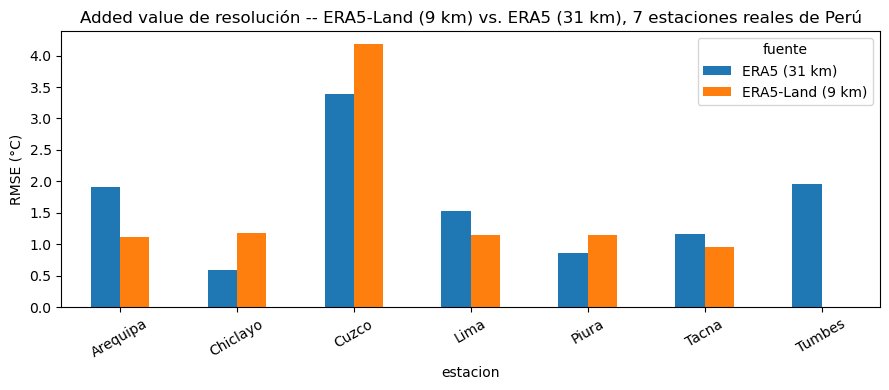

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
tabla_peru["RMSE"].unstack("fuente").plot(kind="bar", ax=ax)
ax.set_ylabel("RMSE (°C)")
ax.set_title("Added value de resolución -- ERA5-Land (9 km) vs. ERA5 (31 km), 7 estaciones reales de Perú")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

## Lectura del resultado (a completar por el grupo)

Igual que en el Módulo 5 con WRF vs. ERA5-Land, no se espera un resultado
"arreglado" a favor del producto de mayor resolución -- el terreno de Perú
(costa árida, sierra alta, selva) es muy heterogéneo, y una diferencia de 9
km a 31 km puede o no importar según cuán abrupto sea el relieve cerca de
cada estación (comparar, por ejemplo, Cuzco/Arequipa -- sierra, terreno
complejo -- contra Piura/Tumbes -- costa plana). Preguntas para la puesta
en común:

- ¿En qué estaciones ERA5-Land (mayor resolución) mejora claramente sobre
  ERA5 estándar? ¿Coincide con las estaciones de terreno más complejo?
- ¿Es consistente esta comparación con la lección del Módulo 5 sobre el
  dominio del WRF, donde el producto de mayor resolución (WRF) tampoco le
  ganó siempre a ERA5-Land?

## Cierre

Entregable de esta extensión (si se completa): este notebook +
`validacion_peru_era5land_vs_era5.csv`. Vuelve al flujo principal del curso
en [`README.md`](../README.md) del Módulo 5.